# How DocDost understands text: tokens, embeddings and attention

DocDost turns every chunk of a document into a vector with **all-MiniLM-L6-v2**, a small Transformer (6 layers, 384 dimensions).
This notebook opens up the three ideas that make that work, using the same model files the app uses:

1. **Tokenization**: how text becomes integer ids (WordPiece), and why it decides my chunk size
2. **Embeddings**: how meaning becomes a vector, and how cosine similarity finds paraphrases that keywords miss
3. **Attention**: the core Transformer operation, written from scratch in NumPy

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from tokenizers import Tokenizer

from docdost.embeddings import MiniLMEmbeddings
from docdost.loaders import load_folder, split_documents
from docdost.config import DOCS_DIR

emb = MiniLMEmbeddings()   # downloads the ONNX model once (~80 MB)
tok = Tokenizer.from_file(str(Path.home() / ".cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx/tokenizer.json"))
tok.no_padding(); tok.no_truncation()   # the saved file pads/cuts to 128; we want the raw token counts
print("Vocabulary size:", tok.get_vocab_size())

Vocabulary size: 30522


## 1. Tokenization

The model never sees letters. A **WordPiece** tokenizer splits text into pieces from a fixed 30,522-entry vocabulary.
Common words stay whole; rare words are split into sub-word pieces (`##` means "joined to the piece before").
Two special tokens wrap every input: `[CLS]` at the start and `[SEP]` at the end.

In [2]:
for text in ["The mess wasted food on weekends",
             "zmto biryani 🍕",
             "doodh wala paid via UPI",
             "Tokenization is unbelievable"]:
    enc = tok.encode(text)
    print(f"{text!r:38} -> {enc.tokens}")

'The mess wasted food on weekends'     -> ['[CLS]', 'the', 'mess', 'wasted', 'food', 'on', 'weekends', '[SEP]']
'zmto biryani 🍕'                       -> ['[CLS]', 'z', '##mt', '##o', 'bi', '##rya', '##ni', '[UNK]', '[SEP]']
'doodh wala paid via UPI'              -> ['[CLS]', 'doo', '##dh', 'wal', '##a', 'paid', 'via', 'up', '##i', '[SEP]']
'Tokenization is unbelievable'         -> ['[CLS]', 'token', '##ization', 'is', 'unbelievable', '[SEP]']


Things to notice:

- English words map to single tokens, but Hinglish and typos (`zmto`, `doodh`) get split into several pieces, so they cost more tokens and carry less clear meaning.
- The emoji becomes `[UNK]` (unknown): this vocabulary has no entry for it.
- The text is lower-cased first: this is the *uncased* model.

### Why this decides the chunk size

The embedding code truncates input at **256 tokens**: anything longer is cut off and never embedded, so the end of an over-long chunk is invisible to search.
(The model was also trained on inputs of up to 128 tokens, so shorter chunks are closer to what it knows.)
DocDost splits by token count (200 tokens + a short header) for exactly this reason. My first version split by characters (800), and this check showed 6 of 49 chunks were over 256 tokens, so their endings were never searched. Checking the current chunks:

61 chunks | tokens per chunk: median 154, max 209
Chunks over the 256-token limit: 0 | over 128 tokens: 38


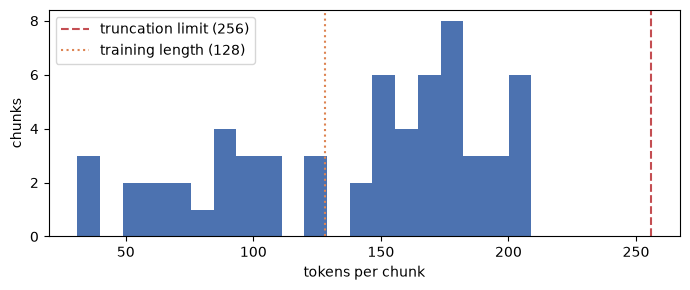

In [3]:
chunks = split_documents(load_folder(DOCS_DIR))
n_tokens = np.array([len(tok.encode(c.page_content).ids) for c in chunks])
print(f"{len(chunks)} chunks | tokens per chunk: median {np.median(n_tokens):.0f}, max {n_tokens.max()}")
print(f"Chunks over the 256-token limit: {(n_tokens > 256).sum()} | over 128 tokens: {(n_tokens > 128).sum()}")

plt.figure(figsize=(7, 3))
plt.hist(n_tokens, bins=20, color="#4C72B0")
plt.axvline(256, color="#C44E52", ls="--", label="truncation limit (256)")
plt.axvline(128, color="#DD8452", ls=":", label="training length (128)")
plt.xlabel("tokens per chunk"); plt.ylabel("chunks"); plt.legend(); plt.tight_layout(); plt.show()

## 2. Embeddings

Each chunk becomes a 384-number vector. The model was trained so that texts with similar **meaning** end up pointing in similar **directions**,
which we measure with cosine similarity: $\cos(a,b) = \frac{a \cdot b}{\|a\|\|b\|}$ (1 = same direction, 0 = unrelated).

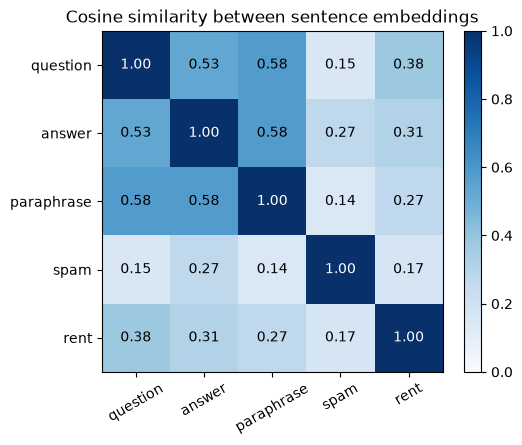

In [4]:
sentences = [
    "How much food did the hostel mess throw away?",       # question
    "23.5% of all food cooked was thrown away.",          # answer, few shared words
    "The mess wasted nearly a quarter of what it cooked.", # paraphrase of the answer
    "The spam filter caught 89% of spam messages.",       # different topic
    "Rent eats 34% of all spending.",                     # different topic
]
E = np.array(emb.embed_documents(sentences))
E = E / np.linalg.norm(E, axis=1, keepdims=True)
S = E @ E.T

labels = ["question", "answer", "paraphrase", "spam", "rent"]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5), labels, rotation=30); ax.set_yticks(range(5), labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", color="white" if S[i, j] > .6 else "black")
plt.colorbar(im); plt.title("Cosine similarity between sentence embeddings"); plt.tight_layout(); plt.show()

The question is clearly closer to the answer (0.53) and its paraphrase (0.58) than to the unrelated sentences (0.15 and 0.38), even though the paraphrase shares almost no words with it. The rent sentence still scores 0.38 because it shares the "% of all ..." pattern, a reminder that similarity scores are relative, not absolute.
This is exactly what keyword search (BM25) can't do, and why DocDost combines both: BM25 for exact terms like `RANK()` or `0.81`, embeddings for meaning.
In my evaluation (`eval/evaluate.py`), embeddings raised hit@4 on paraphrased questions from 64% (BM25) to 86%.

## 3. Attention, from scratch

Inside each of MiniLM's 6 layers, every token looks at every other token and decides how much to borrow from it. That is **scaled dot-product attention**:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- **Q** (queries): what each token is looking for
- **K** (keys): what each token offers
- **V** (values): the information that gets passed along
- Dividing by $\sqrt{d_k}$ keeps the dot products from growing with the dimension, so softmax doesn't saturate.

output shape: (4, 4) | each row of weights sums to [1. 1. 1. 1.]


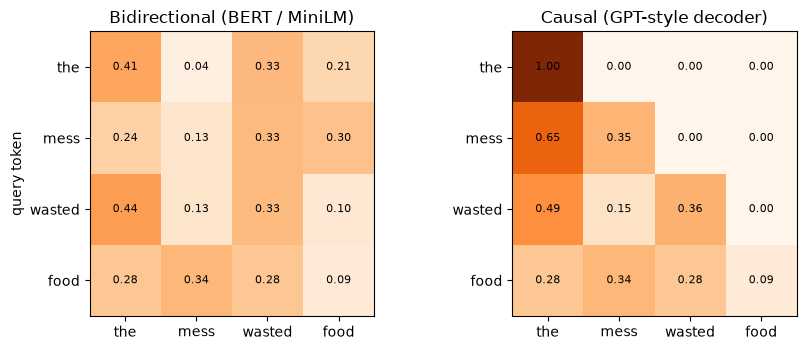

In [5]:
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)   # subtract max for numerical stability
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, causal=False):
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)                 # (tokens x tokens): how well each query matches each key
    if causal:                                       # GPT-style: a token may not look at future tokens
        scores = np.where(np.triu(np.ones_like(scores), k=1) == 1, -np.inf, scores)
    weights = softmax(scores, axis=-1)               # each row sums to 1
    return weights @ V, weights

rng = np.random.default_rng(42)
tokens = ["the", "mess", "wasted", "food"]
d_model, d_k = 8, 4
X = rng.normal(size=(len(tokens), d_model))                       # token embeddings (random here)
W_q, W_k, W_v = (rng.normal(size=(d_model, d_k)) for _ in range(3))  # learned in a real model

out, w_bi = attention(X @ W_q, X @ W_k, X @ W_v)
_, w_causal = attention(X @ W_q, X @ W_k, X @ W_v, causal=True)
print("output shape:", out.shape, "| each row of weights sums to", w_bi.sum(axis=1).round(6))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, w, title in [(axes[0], w_bi, "Bidirectional (BERT / MiniLM)"), (axes[1], w_causal, "Causal (GPT-style decoder)")]:
    ax.imshow(w, cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(4), tokens); ax.set_yticks(range(4), tokens); ax.set_title(title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[0].set_ylabel("query token"); plt.tight_layout(); plt.show()

- **Left:** MiniLM is an *encoder*, so every token attends to every other token in both directions. Good for understanding a whole chunk at once.
- **Right:** the LLMs that write DocDost's answers (Gemini, Llama) are *decoders*: the mask hides future tokens so they can generate text one token at a time.
- A real Transformer runs several of these "heads" in parallel (MiniLM: 12 heads of 32 dimensions = 384), then a feed-forward layer, with residual connections and layer norm around both.

### From token vectors to one sentence vector

MiniLM outputs one 384-d vector per token. To get one vector per chunk, sentence-transformers **mean-pools** the token vectors (ignoring padding) and L2-normalises the result.
That single vector is what DocDost stores in ChromaDB for each chunk.

## Summary

| Idea | What it means for DocDost |
|---|---|
| WordPiece tokenization, 256-token limit | Chunks are measured in tokens (200 + header) so no chunk gets cut off |
| Embeddings + cosine similarity | Finds the right chunk even when the question uses different words |
| Keyword search still matters | Hybrid search keeps exact matches for numbers, names and code |
| Encoder vs decoder attention | A small encoder retrieves; a large decoder LLM writes the answer |